# StyleBot - Entrega 2: preparación común de datos para CNN

**Responsable:** Krysto Alberto Adan Jauregui Zuñiga  
**Semilla común:** 42

Este notebook prepara Fashion-MNIST para las redes neuronales convolucionales de la Entrega 2. Conserva exactamente el protocolo de la Entrega 1: 48,000 imágenes de entrenamiento, 12,000 de validación y 10,000 de prueba. También agrega el canal necesario para las CNN y crea un aumento de datos que solamente se aplica al entrenamiento.

> Este archivo no entrena las arquitecturas CNN. Su objetivo es entregar a todo el equipo los mismos datos y evitar diferencias entre experimentos.

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
tf.keras.utils.set_random_seed(SEMILLA)

try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

CATEGORIAS = [
    'Camiseta/top', 'Pantalón', 'Suéter', 'Vestido', 'Abrigo',
    'Sandalia', 'Camisa', 'Tenis', 'Bolso', 'Botín'
]

print('TensorFlow:', tf.__version__)
print('Semilla común:', SEMILLA)
print('Categorías:', CATEGORIAS)

TensorFlow: 2.21.0
Semilla común: 42
Categorías: ['Camiseta/top', 'Pantalón', 'Suéter', 'Vestido', 'Abrigo', 'Sandalia', 'Camisa', 'Tenis', 'Bolso', 'Botín']


## 1. Carga y división reproducible

Fashion-MNIST contiene 60,000 imágenes oficiales para entrenamiento y 10,000 para prueba. Igual que en la Entrega 1, se separa 20 % de las 60,000 imágenes para validación mediante `train_test_split`, `random_state=42` y `stratify`. El conjunto oficial de prueba permanece intacto.

In [2]:
(X_base, y_base), (X_test_original, y_test) = tf.keras.datasets.fashion_mnist.load_data()

indices = np.arange(len(y_base), dtype=np.int64)
idx_train, idx_val = train_test_split(
    indices,
    test_size=0.20,
    random_state=SEMILLA,
    stratify=y_base
)

X_train = X_base[idx_train].astype('float32') / 255.0
y_train = y_base[idx_train].astype('int64')
X_val = X_base[idx_val].astype('float32') / 255.0
y_val = y_base[idx_val].astype('int64')
X_test = X_test_original.astype('float32') / 255.0
y_test = y_test.astype('int64')

print('División creada con semilla 42 y estratificación.')

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
División creada con semilla 42 y estratificación.


## 2. Forma requerida por las CNN

Las imágenes originales tienen forma `(28, 28)`. Se agrega un canal para obtener `(28, 28, 1)`, que es la entrada común que utilizarán las CNN propias.

In [3]:
X_train = X_train[..., np.newaxis]
X_val = X_val[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print('Entrenamiento:', X_train.shape, y_train.shape)
print('Validación:   ', X_val.shape, y_val.shape)
print('Prueba:       ', X_test.shape, y_test.shape)
print('Tipo:', X_train.dtype)
print('Rango normalizado:', float(X_train.min()), 'a', float(X_train.max()))

Entrenamiento: (48000, 28, 28, 1) (48000,)
Validación:    (12000, 28, 28, 1) (12000,)
Prueba:        (10000, 28, 28, 1) (10000,)
Tipo: float32
Rango normalizado: 0.0 a 1.0


In [4]:
assert X_train.shape == (48000, 28, 28, 1)
assert X_val.shape == (12000, 28, 28, 1)
assert X_test.shape == (10000, 28, 28, 1)
assert X_train.dtype == np.float32
assert 0.0 <= X_train.min() and X_train.max() <= 1.0
assert set(np.unique(y_train)) == set(range(10))

conteos = pd.DataFrame({
    'categoría': CATEGORIAS,
    'entrenamiento': np.bincount(y_train, minlength=10),
    'validación': np.bincount(y_val, minlength=10),
    'prueba': np.bincount(y_test, minlength=10)
})
display(conteos)
print('Comprobaciones correctas: cantidades, forma, categorías y normalización.')

,categoría,entrenamiento,validación,prueba
0,Camiseta/top,4800,1200,1000
1,Pantalón,4800,1200,1000
2,Suéter,4800,1200,1000
3,Vestido,4800,1200,1000
4,Abrigo,4800,1200,1000
5,Sandalia,4800,1200,1000
6,Camisa,4800,1200,1000
7,Tenis,4800,1200,1000
8,Bolso,4800,1200,1000
9,Botín,4800,1200,1000


Comprobaciones correctas: cantidades, forma, categorías y normalización.


## 3. Aumento de datos exclusivo del entrenamiento

Se utilizan transformaciones pequeñas porque las prendas deben conservar su significado. La rotación, traslación y zoom se aplican en tiempo real solamente dentro de `train_ds`. Los conjuntos `val_ds` y `test_ds` no contienen estas transformaciones.

In [5]:
aumento_datos = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.05, fill_mode='nearest', seed=SEMILLA),
    tf.keras.layers.RandomTranslation(0.05, 0.05, fill_mode='nearest', seed=SEMILLA),
    tf.keras.layers.RandomZoom(0.05, fill_mode='nearest', seed=SEMILLA),
], name='aumento_solo_entrenamiento')

BATCH_SIZE = 128
AUTOTUNE = tf.data.AUTOTUNE

train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .shuffle(len(X_train), seed=SEMILLA, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .map(lambda imagenes, etiquetas: (aumento_datos(imagenes, training=True), etiquetas),
         num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(BATCH_SIZE).prefetch(AUTOTUNE)
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(BATCH_SIZE).prefetch(AUTOTUNE)

print('train_ds: incluye aumento de datos')
print('val_ds:   sin aumento de datos')
print('test_ds:  sin aumento de datos')
print('Entrada CNN:', train_ds.element_spec[0].shape)

train_ds: incluye aumento de datos
val_ds:   sin aumento de datos
test_ds:  sin aumento de datos
Entrada CNN: (None, 28, 28, 1)


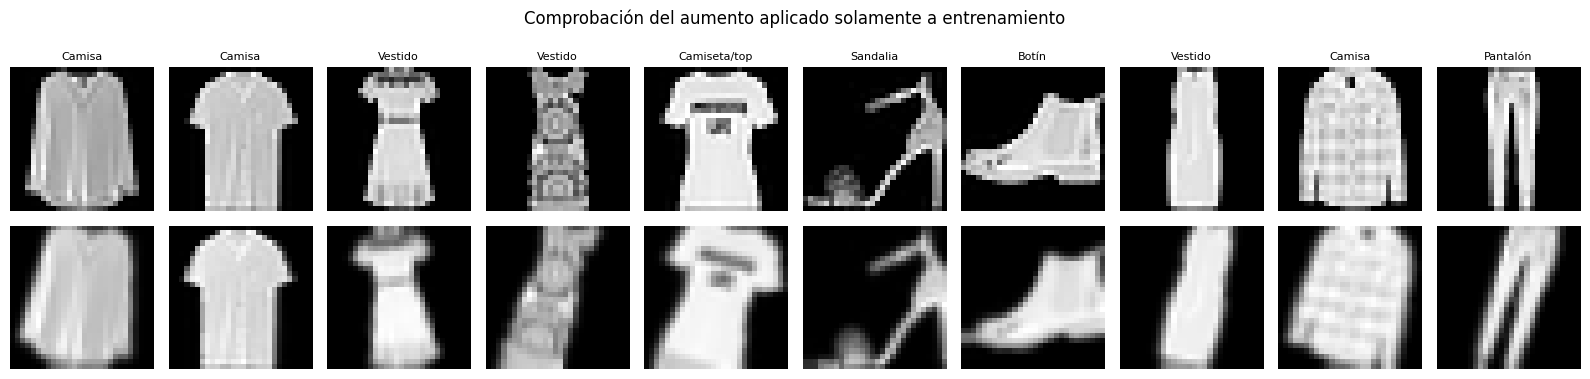

In [6]:
muestra_original = X_train[:10]
muestra_aumentada = aumento_datos(muestra_original, training=True).numpy()

fig, axes = plt.subplots(2, 10, figsize=(16, 4))
for i in range(10):
    axes[0, i].imshow(muestra_original[i].squeeze(), cmap='gray')
    axes[0, i].set_title(CATEGORIAS[y_train[i]], fontsize=8)
    axes[0, i].axis('off')
    axes[1, i].imshow(muestra_aumentada[i].squeeze(), cmap='gray')
    axes[1, i].axis('off')

axes[0, 0].set_ylabel('Original', fontsize=10)
axes[1, 0].set_ylabel('Aumentada', fontsize=10)
plt.suptitle('Comprobación del aumento aplicado solamente a entrenamiento')
plt.tight_layout()
plt.show()

In [7]:
X_val_control = X_val.copy()
X_test_control = X_test.copy()
_ = aumento_datos(X_train[:32], training=True)

assert np.array_equal(X_val, X_val_control)
assert np.array_equal(X_test, X_test_control)
print('Validación confirmada: X_val y X_test permanecen sin aumento.')

Validación confirmada: X_val y X_test permanecen sin aumento.


## 4. Datos que utilizará el equipo

Juan José puede utilizar `X_train`, `y_train`, `X_val`, `y_val`, `X_test` y `y_test` para las tres arquitecturas. Para entrenar con aumento debe utilizar `train_ds`; para validación y prueba debe usar `val_ds` y `test_ds`.

### Resultado esperado

- Entrenamiento: `(48000, 28, 28, 1)`
- Validación: `(12000, 28, 28, 1)`
- Prueba: `(10000, 28, 28, 1)`
- Píxeles: `float32`, entre 0 y 1
- Semilla: 42
- Aumento: solamente en `train_ds`

No se entrenó ninguna CNN en este notebook y no se utilizó prueba para elegir modelos o hiperparámetros.